---
title: 'Solutions: From Score Matching to Diffusion Models'
author: Mark Fuge
format:
    html:
        code-fold: true
        code-summary: "Show Solution Code"
---

These are worked solutions to the exercises at the end of the chapter *From Score Matching to Diffusion Models*.

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
import torch.optim as optim

sys.path.insert(0, '../part2/gen_models')
from gen_models_utilities import create_ring_gaussians, make_loader

plt.style.use('seaborn-v0_8-muted')
sns.set_context('talk')

# The chapter's seeds and ring data
torch.manual_seed(42)
np.random.seed(42)
device = "cpu"
data, _ = create_ring_gaussians(n_samples=5000)

In [2]:
# The chapter's noise schedule, forward process, model and reverse sampler
T = 200

def get_alphas(timesteps=200, beta_start=0.0001, beta_end=0.1):
    """Create the noise schedule parameters alpha and alpha_bar."""
    betas = torch.linspace(beta_start, beta_end, timesteps)
    alphas = 1. - betas
    alphas_cumprod = torch.cumprod(alphas, axis=0)
    return alphas, alphas_cumprod

def forward_diffusion_sample(x_0, t, alphas_cumprod, device="cpu"):
    """Takes an datapoint and a timestep and returns the noisy version."""
    noise = torch.randn_like(x_0)
    sqrt_alphas_cumprod_t = torch.sqrt(alphas_cumprod[t])[:, None]
    sqrt_one_minus_alphas_cumprod_t = torch.sqrt(1. - alphas_cumprod[t])[:, None]

    # send to device
    sqrt_alphas_cumprod_t = sqrt_alphas_cumprod_t.to(device)
    sqrt_one_minus_alphas_cumprod_t = sqrt_one_minus_alphas_cumprod_t.to(device)
    noise = noise.to(device)

    # Equation for x_t
    noisy_x = sqrt_alphas_cumprod_t * x_0 + sqrt_one_minus_alphas_cumprod_t * noise
    return noisy_x, noise


class DiffusionModel(nn.Module):
    def __init__(self, n_steps=200, time_emb_dim=16, hidden_dim=128):
        super().__init__()
        self.time_embed = nn.Embedding(n_steps, time_emb_dim)
        self.net = nn.Sequential(
            nn.Linear(2 + time_emb_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2) # Predicts the noise
        )

    def forward(self, x, t):
        t_emb = self.time_embed(t)
        x_in = torch.cat([x, t_emb], dim=-1)
        return self.net(x_in)


@torch.no_grad()
def reverse_sample(model, n_samples=50, n_steps=T, initial_noise_scale=1.0):
    """Generate samples by running the reverse diffusion process.

    n_steps must be the number of steps T the model was trained with: it rebuilds that noise schedule."""
    model.eval()

    # Start with pure noise
    x = torch.randn(n_samples, 2, device=device) * initial_noise_scale

    # Store trajectory for animation
    trajectory = [x.cpu().numpy()]

    # Get noise schedule
    alphas, alphas_cumprod = get_alphas(timesteps=n_steps)
    betas = 1. - alphas

    for i in range(n_steps - 1, -1, -1):
        t = torch.full((n_samples,), i, device=device, dtype=torch.long)

        # Predict noise
        predicted_noise = model(x, t)

        # Get parameters for this timestep
        alpha_t = alphas[t][:, None]
        alpha_t_cumprod = alphas_cumprod[t][:, None]
        beta_t = betas[t][:, None]

        # The update rule
        coeff = (1. - alpha_t) / torch.sqrt(1. - alpha_t_cumprod)
        x = (1. / torch.sqrt(alpha_t)) * (x - coeff * predicted_noise)

        if i > 0:
            # Add noise for stochastic sampling
            variance = beta_t
            noise = torch.randn_like(x) * torch.sqrt(variance)
            x = x + noise

        trajectory.append(x.cpu().numpy())

    return x.cpu().numpy(), np.array(trajectory)

### Exercise 1: What is wrong with this diffusion model?

In [3]:
#| code-fold: false
#| code-line-numbers: true
class DiffusionModelEx1(nn.Module):
    def __init__(self, n_steps=200, time_emb_dim=16, hidden_dim=128):
        super().__init__()
        self.time_embed = nn.Embedding(n_steps, time_emb_dim)
        self.net = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2) # Predicts the noise
        )

    def forward(self, x, t):
        return self.net(x)

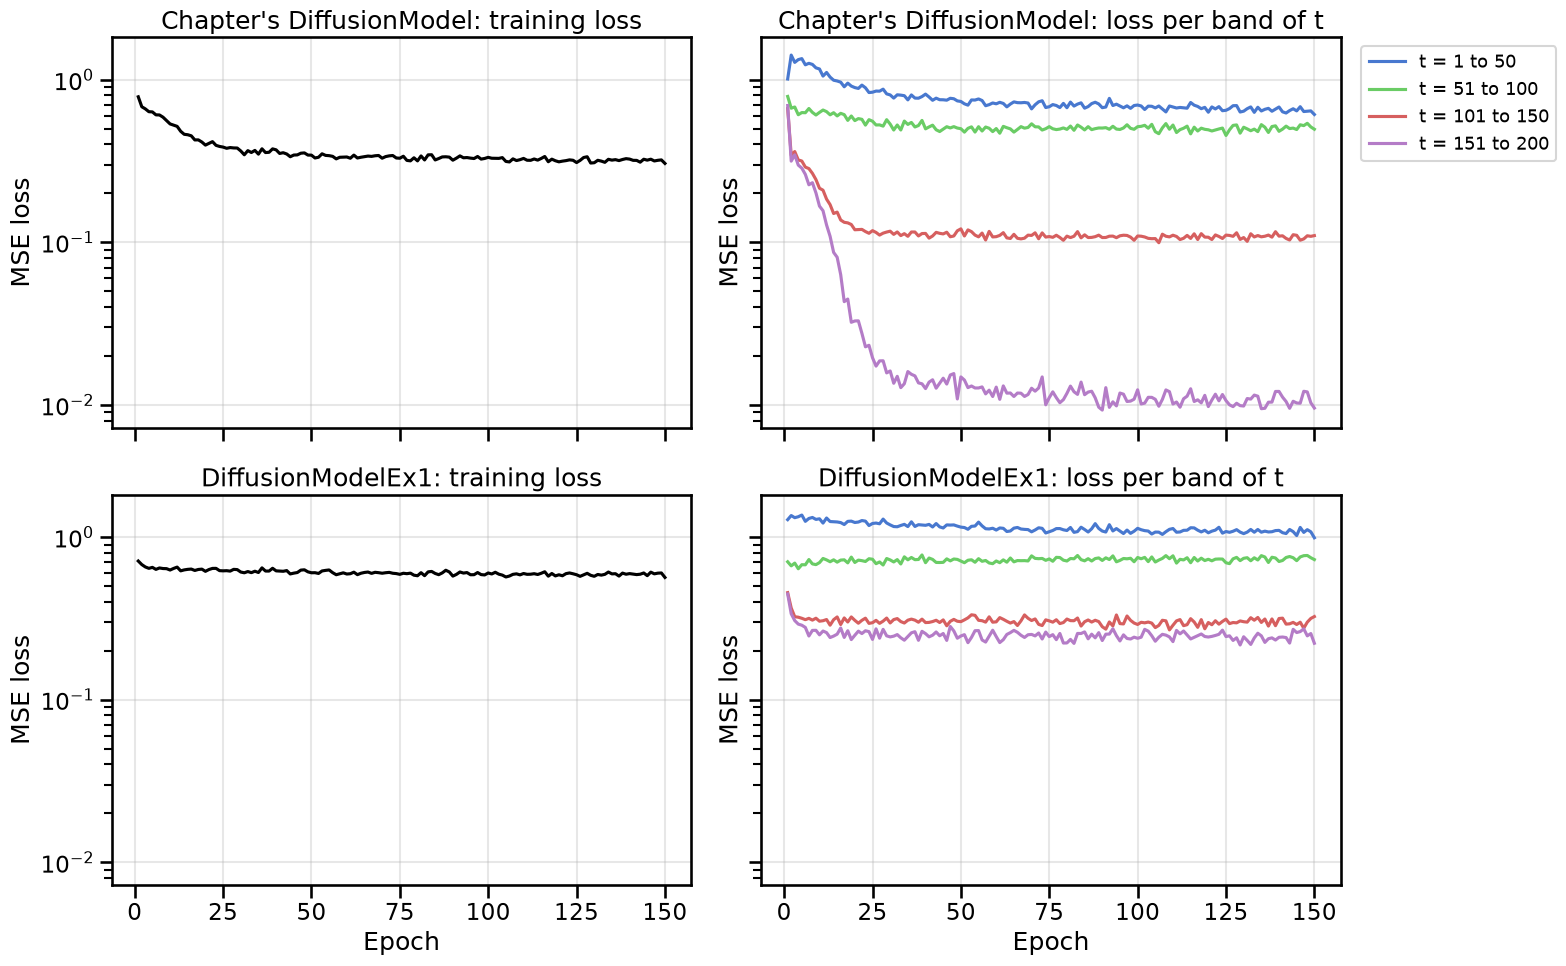

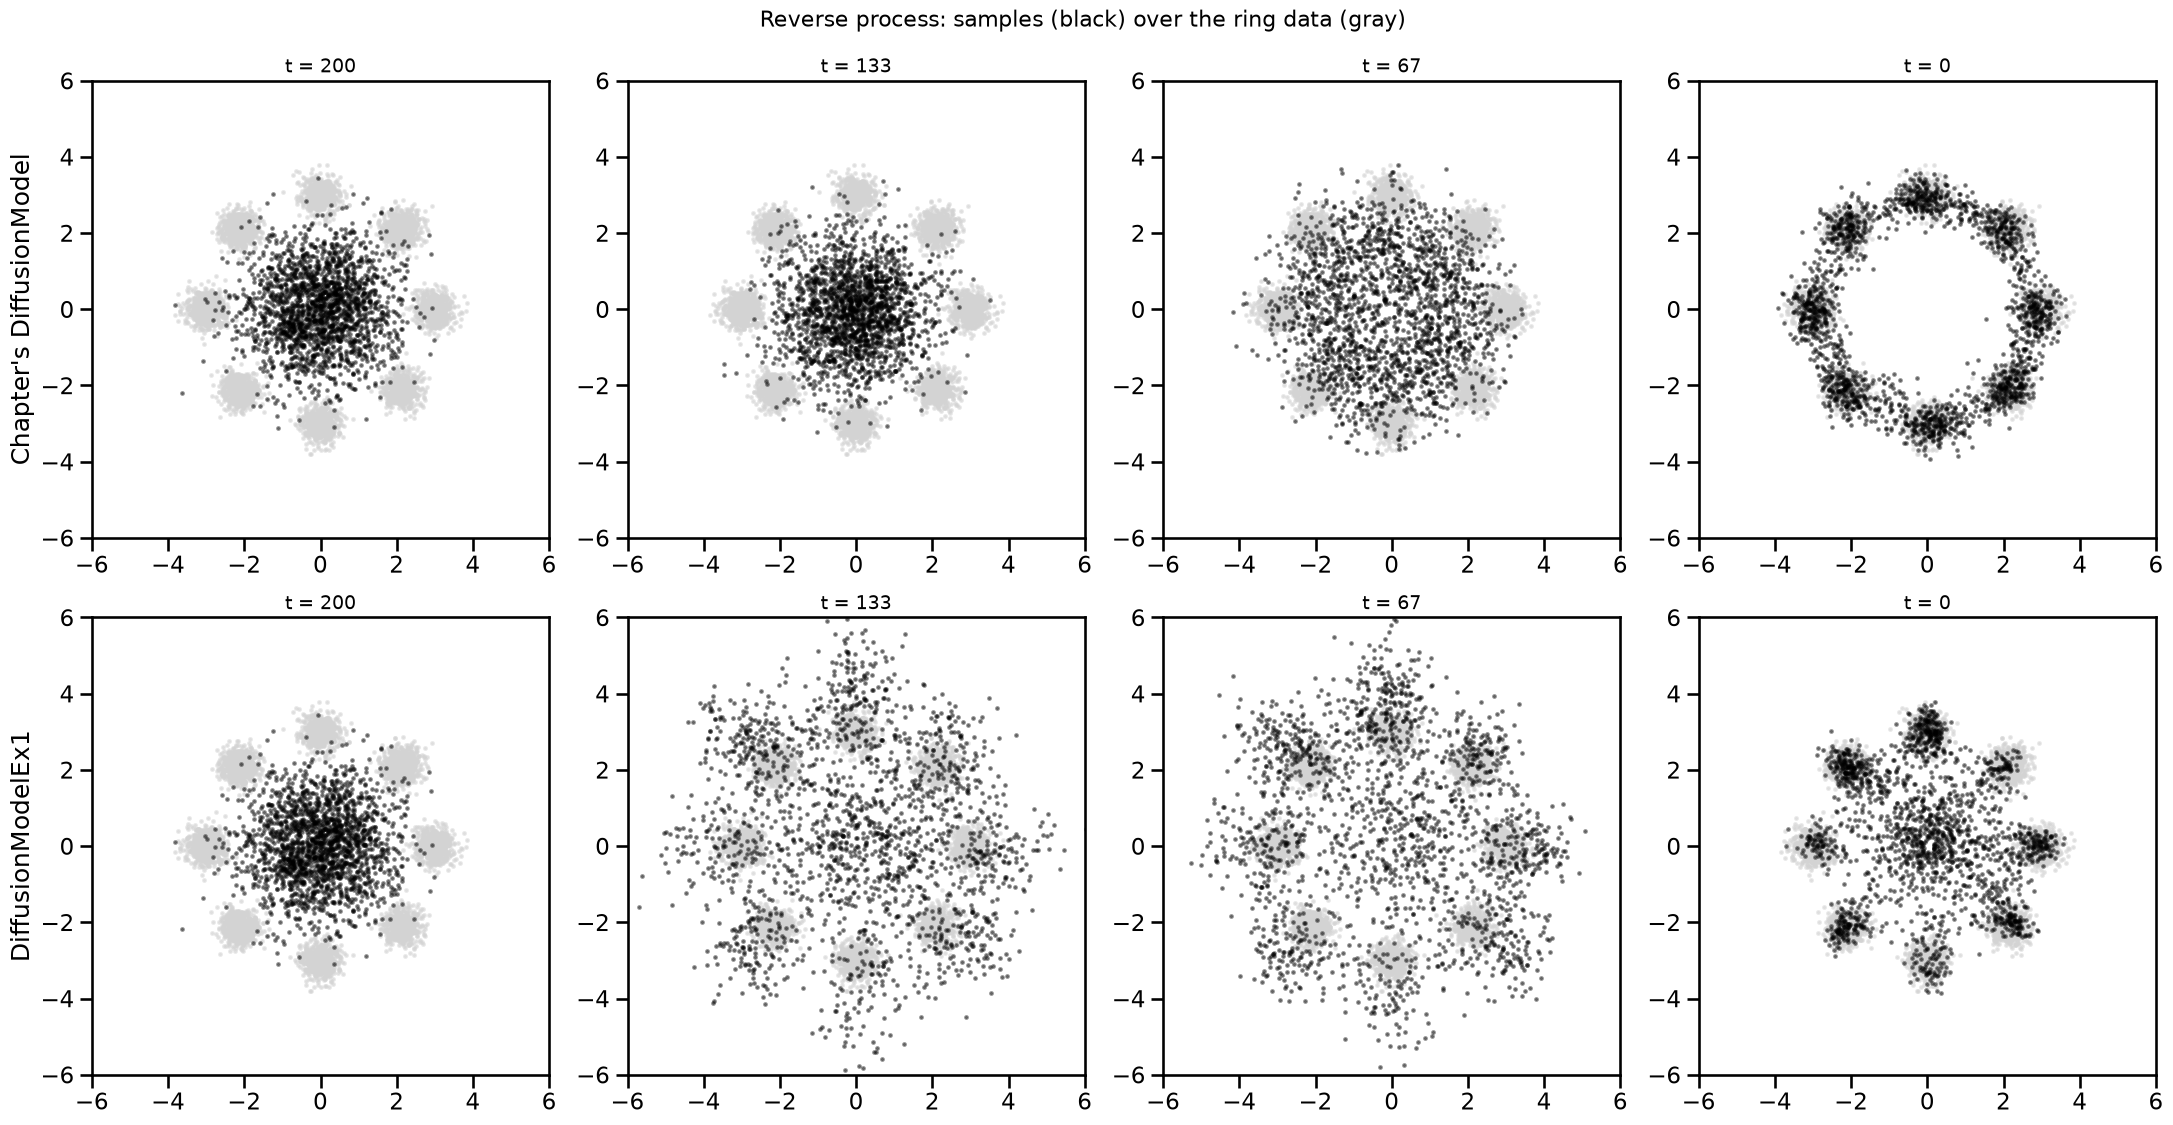

In [ ]:
# Figures for Exercise 1: the chapter's DiffusionModel and DiffusionModelEx1, trained the same way
EX_SEED = 42
EX1_EPOCHS = 150
EX1_BANDS = [(1, 50), (51, 100), (101, 150), (151, 200)]  # bands of t; x_t uses schedule index t - 1
EX1_STEPS = [0, 67, 133, 200]  # reverse steps taken; the samples are then at t = T - steps
_, alphas_cumprod_ex1 = get_alphas(timesteps=T)


def train_with_bands(model, n_epochs=EX1_EPOCHS, batch_size=256, lr=1e-3, seed=EX_SEED):
    # The chapter's training loop; also records the mean loss in each band of t, per epoch
    torch.manual_seed(seed)
    loader_ex1 = make_loader(data, batch_size=batch_size)
    optimizer_ex1 = optim.Adam(model.parameters(), lr=lr)
    epoch_loss, band_loss = [], []
    for epoch in range(n_epochs):
        batch_losses = []
        band_sum = np.zeros(len(EX1_BANDS))
        band_count = np.zeros(len(EX1_BANDS))
        for (x_0,) in loader_ex1:
            t = torch.randint(0, T, (x_0.shape[0],))
            x_t, noise = forward_diffusion_sample(x_0, t, alphas_cumprod_ex1)
            predicted_noise = model(x_t, t)
            loss = nn.functional.mse_loss(predicted_noise, noise)
            optimizer_ex1.zero_grad()
            loss.backward()
            optimizer_ex1.step()
            batch_losses.append(loss.item())
            per_sample = ((predicted_noise - noise) ** 2).mean(dim=1).detach()
            for k, (lo, hi) in enumerate(EX1_BANDS):
                in_band = (t >= lo - 1) & (t < hi)
                band_sum[k] += per_sample[in_band].sum().item()
                band_count[k] += in_band.sum().item()
        epoch_loss.append(np.mean(batch_losses))
        band_loss.append(band_sum / band_count)
    return np.array(epoch_loss), np.array(band_loss)


ex1_models, ex1_loss, ex1_bands, ex1_traj = {}, {}, {}, {}
for name, model_class in [("Chapter's DiffusionModel", DiffusionModel), ('DiffusionModelEx1', DiffusionModelEx1)]:
    torch.manual_seed(EX_SEED)
    ex1_models[name] = model_class(n_steps=T)
    ex1_loss[name], ex1_bands[name] = train_with_bands(ex1_models[name])
    torch.manual_seed(EX_SEED)
    _, ex1_traj[name] = reverse_sample(ex1_models[name], n_samples=2000, n_steps=T)

# Losses: total, and per band of t
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
for row, name in enumerate(ex1_models):
    axes[row, 0].plot(np.arange(1, EX1_EPOCHS + 1), ex1_loss[name], color='k')
    axes[row, 0].set_title(f'{name}: training loss')
    for k, (lo, hi) in enumerate(EX1_BANDS):
        axes[row, 1].plot(np.arange(1, EX1_EPOCHS + 1), ex1_bands[name][:, k], label=f't = {lo} to {hi}')
    axes[row, 1].set_title(f'{name}: loss per band of t')
    for ax in axes[row]:
        ax.set_yscale('log')
        ax.set_ylabel('MSE loss of predicted noise')
        ax.grid(True, alpha=0.3)
axes[0, 1].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), fontsize=13)
for ax in axes[1]:
    ax.set_xlabel('Epoch')
plt.tight_layout()
plt.show()

# Reverse-process snapshots
fig, axes = plt.subplots(2, 4, figsize=(22, 11.5))
for row, name in enumerate(ex1_models):
    for col, steps in enumerate(EX1_STEPS):
        ax = axes[row, col]
        ax.scatter(data[:, 0], data[:, 1], s=4, color='lightgrey', alpha=0.5)
        ax.scatter(ex1_traj[name][steps][:, 0], ex1_traj[name][steps][:, 1], s=4, color='k', alpha=0.4)
        ax.set_xlim(-6, 6)
        ax.set_ylim(-6, 6)
        ax.set_aspect('equal')
        ax.set_title(f't = {T - steps}', fontsize=14)
    axes[row, 0].set_ylabel(name)
fig.suptitle('Reverse process: samples (black) over the ring data (gray)', fontsize=16)
plt.tight_layout()
plt.show()

In [5]:
# Numbers behind the answers to Exercise 1
print("Mean loss over the last 10 epochs (and in the first epoch):")
for name in ex1_models:
    bands_end = ex1_bands[name][-10:].mean(axis=0)
    print(f"  {name:25s} total {ex1_loss[name][-10:].mean():.3f} (first epoch {ex1_loss[name][0]:.3f}); "
          + "bands t = 1-50, 51-100, 101-150, 151-200: " + ", ".join(f"{v:.3f}" for v in bands_end))
print("Training loss in epochs 1, 5, 10, 25 and 150:")
for name in ex1_models:
    print(f"  {name:25s} " + ", ".join(f"{ex1_loss[name][e - 1]:.3f}" for e in [1, 5, 10, 25, 150]))

# How the noise prediction depends on x_t at a high-noise step: least-squares slope of eps_hat on x_t
t_probe = 180  # x_t at t = 180 uses schedule index 179
x_probe = torch.randn(4000, 2, generator=torch.Generator().manual_seed(EX_SEED))
with torch.no_grad():
    for name, model in ex1_models.items():
        model.eval()
        eps_hat = model(x_probe, torch.full((4000,), t_probe - 1, dtype=torch.long))
        slope = (eps_hat * x_probe).sum() / (x_probe * x_probe).sum()
        print(f"  {name:25s} slope of eps_hat on x_t at t = {t_probe}: {slope.item():.2f}")

alphas_ex1, _ = get_alphas(timesteps=T)
print(f"Growth of x over the first 67 reverse steps if eps_hat were 0: {torch.prod(1 / alphas_ex1[133:].sqrt()).item():.1f}")

ring_centers = 3.0 * np.stack([np.cos(np.linspace(0, 2 * np.pi, 8, endpoint=False)),
                               np.sin(np.linspace(0, 2 * np.pi, 8, endpoint=False))], axis=1)
print(f"Reverse-process samples (the ring data has variance per coordinate {data.var(axis=0).mean():.2f}):")
for name in ex1_models:
    for steps in EX1_STEPS:
        x = ex1_traj[name][steps]
        r = np.linalg.norm(x, axis=1)
        near = np.linalg.norm(x[:, None] - ring_centers, axis=2).min(axis=1) < 0.75
        print(f"  {name:25s} t = {T - steps:3d}: variance per coordinate {x.var(axis=0).mean():5.2f}, "
              f"farther than 5 from the origin {np.mean(r > 5):.3f}, within 1 of the origin {np.mean(r < 1):.3f}, "
              f"within 0.75 of a mode center {near.mean():.3f}")

Mean loss over the last 10 epochs (and in the first epoch):
  Chapter's DiffusionModel  total 0.318 (first epoch 0.785); bands t = 1-50, 51-100, 101-150, 151-200: 0.643, 0.511, 0.108, 0.011
  DiffusionModelEx1         total 0.592 (first epoch 0.712); bands t = 1-50, 51-100, 101-150, 151-200: 1.072, 0.745, 0.300, 0.250
Training loss in epochs 1, 5, 10, 25 and 150:
  Chapter's DiffusionModel  0.785, 0.634, 0.535, 0.385, 0.306
  DiffusionModelEx1         0.712, 0.651, 0.627, 0.620, 0.564
  Chapter's DiffusionModel  slope of eps_hat on x_t at t = 180: 0.97
  DiffusionModelEx1         slope of eps_hat on x_t at t = 180: 0.56
Growth of x over the first 67 reverse steps if eps_hat were 0: 18.5
Reverse-process samples (the ring data has variance per coordinate 4.56):
  Chapter's DiffusionModel  t = 200: variance per coordinate  0.99, farther than 5 from the origin 0.000, within 1 of the origin 0.396, within 0.75 of a mode center 0.036
  Chapter's DiffusionModel  t = 133: variance per coordinat

**(a)** Line 14, `return self.net(x)`. The model takes `t` as an input and even has a time embedding (line 4), but it never passes `t` to the network. So the network predicts the noise from $x_t$ alone. To fix it, line 14 must concatenate `x` with `self.time_embed(t)`, and line 6 must take `2 + time_emb_dim` inputs, as in the chapter's `DiffusionModel`. A diffusion model has to predict the noise in $x_t$ at the noise level $t$. The same point $x$ is nearly clean data at $t = 10$ and nearly pure noise at $t = 190$. The noise in it is different in the two cases. Without $t$, the network has to give one answer for both.

**(b)** Three features of the plots point to the missing $t$.

The training loss levels off early and stays high. By epoch 10 the loss of `DiffusionModelEx1` is 0.627 (0.712 in the first epoch). After that it barely moves: 0.620 at epoch 25 and a mean of 0.592 over the last 10 epochs. The chapter's model keeps improving: 0.535 at epoch 10, 0.385 at epoch 25 and 0.318 over the last 10 epochs. Without $t$, the best the network can learn is $E[\epsilon \mid x_t = x]$. This is the noise we expect at $x$, averaged over all the times $t$ that could have produced $x$. It is one smooth function of $x$, and the network learns it in a few epochs. At any single $t$ this average is wrong. More training cannot fix that, because the input does not contain $t$.

The largest gap is in the band $t = 151$ to 200. There the chapter's model reaches 0.011, and `DiffusionModelEx1` stays at 0.250, more than 20 times higher. In the other bands the two losses differ by less than a factor of 3. In this band $\sqrt{\bar\alpha_t} \le 0.06$, so $x_t \approx \epsilon$ and the right answer is $\hat\epsilon \approx x_t$. The chapter's model learns this. At $t = 180$, the slope of its $\hat\epsilon$ on $x_t$ is 0.97. `DiffusionModelEx1` cannot tell pure noise from a low-$t$ sample at the same place, and its compromise has a slope of 0.56. Knowing $t$ helps most in this band, because only here does it make the task easy. In the band $t = 1$ to 50 both models do worst (0.643 and 1.072). There the noise is a small part of $x_t$ and hard to separate from the data, with or without $t$.

The reverse process goes wrong from the first steps. Both models start from the same $\mathcal{N}(0, I)$ samples at $t = 200$. With the chapter's model, the samples are still a blob at $t = 133$ (variance per coordinate 1.02). They spread out by $t = 67$ (2.18) and form the ring at $t = 0$, with 0.759 of them within 0.75 of a mode center. With `DiffusionModelEx1`, the samples fly apart right away. At $t = 133$ their variance is already 5.33, more than the 4.56 of the ring data, and 0.045 of them lie farther than 5 from the origin. The ring also shows up far too early. At $t = 133$, 0.235 of the samples are within 0.75 of a mode center, against 0.044 for the chapter's model. At $t = 0$ a cluster is left at the center (0.177 within 1 of the origin, none for the chapter's model), and only 0.516 of the samples sit near a mode.

The cause is the division by $\sqrt{\alpha_t}$ in each reverse step. With $\beta_t$ near 0.1, it makes $x$ about 5% larger per step, and 18.5 times larger over the first 67 steps. At high $t$, only the prediction $\hat\epsilon \approx x_t$ cancels this growth. A slope of 0.56 cancels only part of it, so the samples blow up. At low $t$ the averaged prediction is wrong again (band loss 1.072), so the last steps do not pull every sample onto a mode.

### Exercise 2: What the denoiser predicts

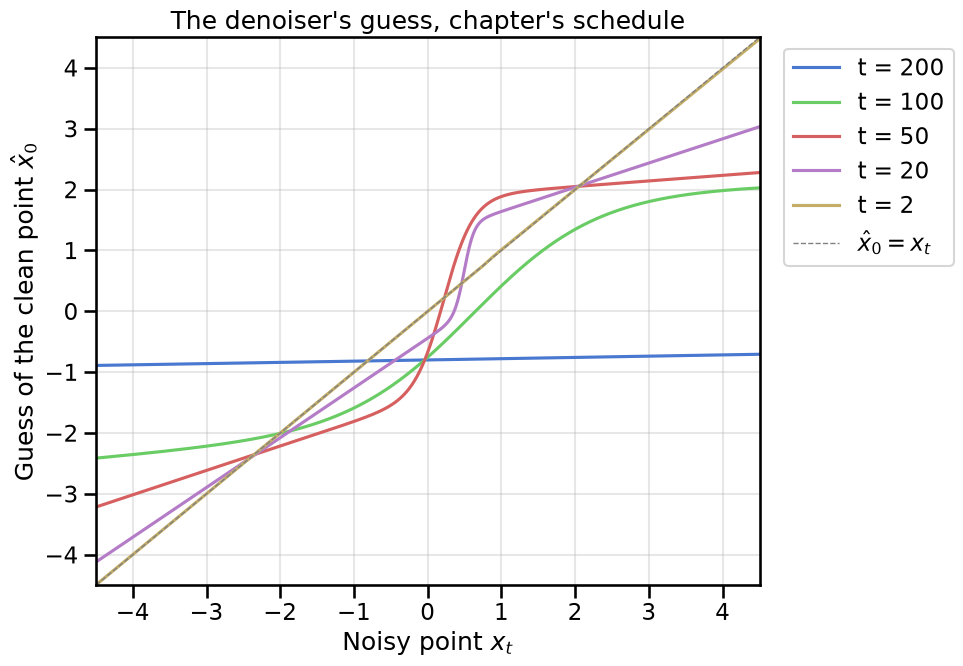

In [6]:
# Figure for Exercise 2: the denoiser's guess of the clean point, from the exact noise of a 1D mixture
MIX_W = np.array([0.7, 0.3])
MIX_MU = np.array([-2.0, 2.0])
MIX_SD = np.array([0.6, 0.25])
EX2_TIMES = [200, 100, 50, 20, 2]
alphas_cumprod_ex2 = get_alphas(timesteps=T)[1].double().numpy()  # the chapter's schedule


def mix_t_components(x, alpha_bar):
    # Weighted components of p_t: means sqrt(alpha_bar) mu_k, variances alpha_bar sd_k^2 + 1 - alpha_bar
    means = np.sqrt(alpha_bar) * MIX_MU
    var = alpha_bar * MIX_SD ** 2 + 1 - alpha_bar
    return MIX_W * np.exp(-0.5 * (x[:, None] - means) ** 2 / var) / np.sqrt(2 * np.pi * var), means, var


def mix_t_score(x, alpha_bar):
    # d/dx log p_t(x): each component's score, weighted by its share of p_t(x)
    comps, means, var = mix_t_components(x, alpha_bar)
    resp = comps / comps.sum(axis=1, keepdims=True)
    return (resp * (-(x[:, None] - means) / var)).sum(axis=1)


def alpha_bar_at(alphas_cumprod_1d, t):
    # alpha_bar of x_t; t = 0 is the data
    return 1.0 if t == 0 else alphas_cumprod_1d[t - 1]


xs_1d = np.linspace(-4.5, 4.5, 1801)
fig, ax = plt.subplots(figsize=(10, 7))
for t in EX2_TIMES:
    alpha_bar_t = alpha_bar_at(alphas_cumprod_ex2, t)
    eps_hat = -np.sqrt(1 - alpha_bar_t) * mix_t_score(xs_1d, alpha_bar_t)
    x0_hat = (xs_1d - np.sqrt(1 - alpha_bar_t) * eps_hat) / np.sqrt(alpha_bar_t)
    ax.plot(xs_1d, x0_hat, label=f't = {t}')
ax.plot(xs_1d, xs_1d, color='0.5', linestyle='--', linewidth=1, label=r'$\hat{x}_0 = x_t$')
ax.set_xlim(-4.5, 4.5)
ax.set_ylim(-4.5, 4.5)
ax.set_xlabel('Noisy point $x_t$')
ax.set_ylabel(r'Guess of the clean point $\hat{x}_0$')
ax.set_title("The denoiser's guess, chapter's schedule")
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# Numbers behind the answers to Exercise 2
print(f"Mean of p(x): {np.sum(MIX_W * MIX_MU):.2f}")
x_show = np.array([-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0])
print("x_t:     " + " ".join(f"{v:6.1f}" for v in x_show))
for t in EX2_TIMES:
    alpha_bar_t = alpha_bar_at(alphas_cumprod_ex2, t)
    eps_hat = -np.sqrt(1 - alpha_bar_t) * mix_t_score(x_show, alpha_bar_t)
    x0_hat = (x_show - np.sqrt(1 - alpha_bar_t) * eps_hat) / np.sqrt(alpha_bar_t)
    print(f"t = {t:3d}: " + " ".join(f"{v:6.2f}" for v in x0_hat)
          + f"   (sigma_t = {np.sqrt(1 - alpha_bar_t):.3f})")

# Within one mode, the guess moves with x_t at the rate sqrt(alpha_bar) sd^2 / (alpha_bar sd^2 + 1 - alpha_bar)
alpha_bar_50 = alpha_bar_at(alphas_cumprod_ex2, 50)
rates = np.sqrt(alpha_bar_50) * MIX_SD ** 2 / (alpha_bar_50 * MIX_SD ** 2 + 1 - alpha_bar_50)
print(f"t = 50: rate inside the left mode (sd 0.6) {rates[0]:.2f}, inside the right mode (sd 0.25) {rates[1]:.2f}")

Mean of p(x): -0.80
x_t:       -3.0   -2.0   -1.0    0.0    1.0    2.0    3.0
t = 200:  -0.86  -0.84  -0.82  -0.80  -0.78  -0.76  -0.74   (sigma_t = 1.000)
t = 100:  -2.22  -2.01  -1.59  -0.75   0.42   1.35   1.80   (sigma_t = 0.960)
t =  50:  -2.62  -2.22  -1.81  -0.67   1.89   2.05   2.14   (sigma_t = 0.682)
t =  20:  -2.90  -2.08  -1.26  -0.44   1.64   2.04   2.44   (sigma_t = 0.305)
t =   2:  -3.00  -2.00  -1.00  -0.00   1.01   2.00   2.99   (sigma_t = 0.026)
t = 50: rate inside the left mode (sd 0.6) 0.40, inside the right mode (sd 0.25) 0.09


**(a)** At $t = 200$, $\bar\alpha_T \approx 3 \cdot 10^{-5}$, so $x_t$ tells us almost nothing about $x_0$. With the ideal noise prediction, $\hat{x}_0$ is the mean of the clean points that could have produced $x_t$. When $x_t$ carries no information, this is the mean of $p(x)$, which is $0.7 \cdot (-2) + 0.3 \cdot 2 = -0.8$. The curve runs from $-0.86$ at $x_t = -3$ to $-0.74$ at $x_t = 3$.

**(b)** At $t = 50$ ($\sigma_t = 0.68$) the two modes of $p_t$ are well apart. For most $x_t$ we can be almost sure which mode the clean point came from. So the guess lies close to the center of that mode: $-2.22$ at $x_t = -2$ and $2.05$ at $x_t = 2$. Between the modes, near $x_t \approx 0.3$, both modes are possible, and the guess jumps from one to the other. Inside a mode, the guess still moves with $x_t$, at the rate $\sqrt{\bar\alpha_t}\, \sigma_k^2 / (\bar\alpha_t \sigma_k^2 + 1 - \bar\alpha_t)$. This rate is 0.40 for the wide left mode and 0.09 for the narrow right one. A narrow mode has sampled points already nearby the clean points, so the noisy point doesn't need to add much noise. In contrast, in the a wide mode, the clean point can lie anywhere in a quite a large range.

**(c)** At $t = 2$, $\sigma_t = 0.026$. Almost no noise has been added, so the clean point is almost $x_t$ itself. For example, the guess is $-1.00$ at $x_t = -1$ and $1.01$ at $x_t = 1$.

**(d)** In Exercise 1, the chapter's model reached a loss of 0.011 in the band $t = 151$ to 200 and 0.643 in the band $t = 1$ to 50. At high $t$, $x_t \approx \epsilon$. The noise is easy to predict, but the clean point is lost, and the best guess is the mean of the data, as in (a). At low $t$ it is the other way around. Here $x_t \approx x_0$, so the clean point is easy to guess, as in (c). But the noise is only a small part of $x_t$. If we solve the forward process for $\epsilon$, we get $\epsilon - \hat\epsilon = \frac{\sqrt{\bar\alpha_t}}{\sqrt{1 - \bar\alpha_t}} (\hat{x}_0 - x_0)$. So when $\sigma_t$ is small, a small error in the guess of the clean point becomes a large error in the noise. Predicting the noise and predicting the clean point are the same task. The loss on $\epsilon$ weights the error very differently at different $t$.